# 01 - Target Variable Analysis (Risk)

**Project:** German Credit Risk
**Dataset:** `data/german_credit_data.csv` (1,000 loan applicants, 10 columns plus an index column)
**Author:** Divya Akbari

**Goal of this notebook**
1. Inspect the target variable `Risk`.
2. Calculate the number and percentage of good-risk and bad-risk customers.

`Risk` tells us whether a customer was a **good** credit risk (paid back as agreed) or a **bad** credit risk.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 120)

## 1. Load the data

In [2]:
df = pd.read_csv('data/german_credit_data.csv')

# The first column is only a row number saved from an earlier export, so we remove it
df = df.drop(columns=['Unnamed: 0'])

print('Rows:', df.shape[0])
print('Columns:', df.shape[1])
df.head()

Rows: 1000
Columns: 10


,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


## 2. Inspect the target variable `Risk`

In [3]:
print('Data type      :', df['Risk'].dtype)
print('Unique values  :', sorted(df['Risk'].unique()))
print('Missing values :', df['Risk'].isna().sum())

Data type      : str
Unique values  : ['bad', 'good']
Missing values : 0


`Risk` has only two values, `good` and `bad`, and no missing values.
So this is a **binary (two-class) target**, which is what a credit-risk classification model needs.

## 3. Good-risk and bad-risk counts and percentages

In [4]:
risk_counts = df['Risk'].value_counts()
risk_percent = df['Risk'].value_counts(normalize=True) * 100

risk_table = pd.DataFrame({
    'Count': risk_counts,
    'Percentage (%)': risk_percent.round(1)
})
risk_table.loc['Total'] = [risk_counts.sum(), risk_percent.sum().round(1)]
risk_table

,Count,Percentage (%)
Risk,,
good,700.0,70.0
bad,300.0,30.0
Total,1000.0,100.0


In [5]:
good = risk_counts['good']
bad = risk_counts['bad']

print('Good risk :', good, 'customers')
print('Bad risk  :', bad, 'customers')
print('Ratio     : about', round(good / bad, 2), 'good customers for every 1 bad customer')
print('If a model always guessed "good", it would already be', round(good / len(df) * 100, 1), '% accurate')

Good risk : 700 customers
Bad risk  : 300 customers
Ratio     : about 2.33 good customers for every 1 bad customer
If a model always guessed "good", it would already be 70.0 % accurate


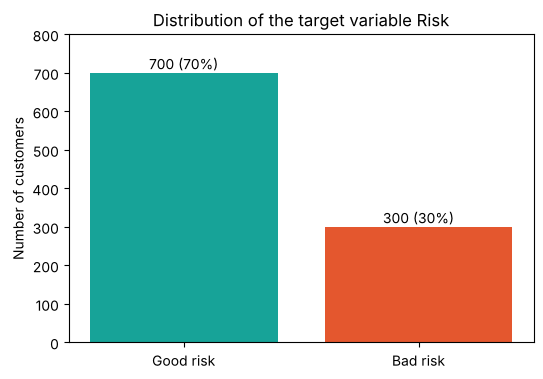

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['Good risk', 'Bad risk'], [good, bad], color=['#17A398', '#E4572E'])

# Write the count and percentage on top of each bar
for bar, value in zip(bars, [good, bad]):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 10,
            f'{value} ({value / len(df) * 100:.0f}%)', ha='center')

ax.set_title('Distribution of the target variable Risk')
ax.set_ylabel('Number of customers')
ax.set_ylim(0, 800)
plt.show()

## 4. Quick checks
These checks confirm the numbers above are correct before they go into the report.

In [7]:
assert len(df) == 1000, 'Expected 1,000 customers'
assert df['Risk'].isna().sum() == 0, 'Risk should have no missing values'
assert set(df['Risk'].unique()) == {'good', 'bad'}, 'Risk should only be good or bad'
assert good + bad == len(df), 'Good + bad should equal all customers'
assert round(risk_percent.sum(), 1) == 100.0, 'Percentages should add up to 100'
print('All 5 checks passed')

All 5 checks passed


## 5. Observations

- **700 customers (70%) are good risk and 300 customers (30%) are bad risk.**
- The target is **imbalanced** (about 2.3 good customers for every bad customer), but not severely.
- A model that always predicts "good" would be 70% accurate while catching **no** bad customers,
  so accuracy alone is not a good measure. Recall for the bad class, precision, F1 and ROC-AUC are better choices.
- When the data is split into train and test sets, the split should be **stratified** on `Risk`
  so both sets keep the same 70/30 balance.